# Search Evaluation: BM25 vs Vector vs Hybrid

We test the three search modes on **TREC-COVID**, the official search benchmark for CORD-19.
Medical experts have already judged which papers answer each question, so we only need to
check **how many of each mode's top 10 results the experts marked as relevant**.

1. Load the expert answer key
2. Run the three search modes
3. Two simple scores
4. Score every question
5. Compare the modes

In [18]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt

from searching.api import es, embeddings, reciprocal_rank_fusion, CANDIDATES

## 1. The expert answer key

The index holds **1,453 CORD-19 papers** sampled from TREC-COVID.

`trec_covid_evaluator.csv` lists, for each of the 10 questions, which papers the experts judged:
- `trec_score`: the experts' grade, 2 = highly relevant, 1 = partly relevant, 0 = not relevant
- `relevant`: 1 if the grade is 1 or 2, otherwise 0

Any paper not listed for a question counts as not relevant.

In [19]:
print("Papers in index:", es.es.count(index=es.name)["count"])

key = pd.read_csv("trec_covid_evaluator.csv")
key.head()

Papers in index: 1453


,query_id,query,cord_uid,title,trec_score,relevant
0,q01,what is the origin of COVID-19,0lywkro9,Spillover of SARS-CoV-2 into novel wild hosts ...,2,1
1,q01,what is the origin of COVID-19,0y34yxlb,Predicting the evolution Of SARS-Covid-2 in Po...,2,1
2,q01,what is the origin of COVID-19,1mjaycee,"COVID-19 infection: Origin, transmission, and ...",2,1
3,q01,what is the origin of COVID-19,22fc1qly,Emerging novel coronavirus (2019-nCoV)-current...,2,1
4,q01,what is the origin of COVID-19,23yi8so0,Non-Molecular-Clock-Like Evolution following V...,2,1


In [20]:
key.groupby(["query_id", "query"])["relevant"].agg(judged="count", relevant="sum")

,,judged,relevant
query_id,query,,
q01,what is the origin of COVID-19,240,87
q02,how does the coronavirus respond to changes in the weather,199,42
q18,what are the best masks for preventing infection by Covid-19?,214,84
q24,what kinds of complications related to COVID-19 are associated with diabetes,214,72
q26,what are the initial symptoms of Covid-19?,252,106
q30,is remdesivir an effective treatment for COVID-19,226,90
q33,What vaccine candidates are being tested for Covid-19?,204,45
q42,Does Vitamin D impact COVID-19 prevention and treatment?,170,60
q45,How has the COVID-19 pandemic impacted mental health?,173,127


In [21]:
queries = key[["query_id", "query"]].drop_duplicates()

relevant = {}
for row in key[key["relevant"] == 1].itertuples():
    relevant.setdefault(row.query_id, set()).add(row.cord_uid)

## 2. The three search modes

Same code as the app. Each returns the top 10 paper IDs.

In [22]:
def paper_id(hit):
    return hit["_source"]["path"].split("/")[-1].replace(".txt", "")


def bm25(query):
    return [paper_id(h) for h in es.search(query, size=10)]


def vector(query):
    hits = es.search_embedding(embeddings.embed(query), field="chunks.embedding", k=10)
    return [paper_id(h) for h in hits]


def hybrid(query):
    bm25_hits = es.search(query, size=CANDIDATES)
    vector_hits = es.search_embedding(embeddings.embed(query), field="chunks.embedding", k=CANDIDATES)
    return [paper_id(h) for h in reciprocal_rank_fusion([bm25_hits, vector_hits])[:10]]


MODES = {"BM25": bm25, "Vector": vector, "Hybrid": hybrid}

## 3. Two simple scores

- **Precision@10**: how many of the top 10 are relevant, divided by 10.
  *7 relevant out of 10 → 0.7*
- **MRR** (reciprocal rank): how high the **first** relevant paper appears.
  *First relevant at rank 1 → 1.0, at rank 2 → 0.5, at rank 4 → 0.25, none → 0*

In [23]:
def precision_at_10(results, relevant_ids):
    hits = sum(1 for pid in results[:10] if pid in relevant_ids)
    return hits / 10


def reciprocal_rank(results, relevant_ids):
    for rank, pid in enumerate(results, start=1):
        if pid in relevant_ids:
            return 1 / rank
    return 0

In [24]:
example = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j"]
example_relevant = {"b", "e", "f"}

print("Precision@10:", precision_at_10(example, example_relevant))
print("MRR:         ", reciprocal_rank(example, example_relevant))

Precision@10: 0.3
MRR:          0.5


## 4. Score every question

Example first: the top 10 for one question, with ✓ where the experts marked the paper relevant.

In [25]:
example_id = "q26"
query = queries.set_index("query_id").loc[example_id, "query"]
print("Question:", query)

pd.DataFrame({
    mode: [f"{pid} {'✓' if pid in relevant[example_id] else ''}" for pid in search(query)]
    for mode, search in MODES.items()
}, index=range(1, 11))

Question: what are the initial symptoms of Covid-19?


,BM25,Vector,Hybrid
1,hlhhvmtu,bdvnwrd4 ✓,hlhhvmtu
2,wtjlqhv4,oxc6nzee ✓,99c1wgid ✓
3,y883anmp,hlhhvmtu,1z0kn95v ✓
4,khfiy0m2,fntwg3g8 ✓,vhtc0jvq ✓
5,ki7bn67o,33ixlhxc ✓,rl97yez3 ✓
6,7j98rhr8,9eijle5e,ecen7ke8 ✓
7,ayunmlpk ✓,jsjxdmi2 ✓,qy7dsyz0 ✓
8,tqrjb1fe ✓,es0pi6ve,fqsmfuxl ✓
9,zcdvql6t,tnorzarg ✓,kanm3n1u ✓
10,edevlflf ✓,dgnw57d2,16rgt4ca ✓


In [26]:
rows = []
for q in queries.itertuples():
    for mode, search in MODES.items():
        results = search(q.query)
        rows.append({
            "query_id": q.query_id,
            "query": q.query,
            "mode": mode,
            "Precision@10": precision_at_10(results, relevant.get(q.query_id, set())),
            "MRR": reciprocal_rank(results, relevant.get(q.query_id, set())),
        })

scores = pd.DataFrame(rows)
scores.pivot_table(index=["query_id", "query"], columns="mode", values="Precision@10")[["BM25", "Vector", "Hybrid"]]

,mode,BM25,Vector,Hybrid
query_id,query,,,
q01,what is the origin of COVID-19,0.2,0.5,0.5
q02,how does the coronavirus respond to changes in the weather,0.1,1.0,0.6
q18,what are the best masks for preventing infection by Covid-19?,0.7,0.9,1.0
q24,what kinds of complications related to COVID-19 are associated with diabetes,0.8,1.0,1.0
q26,what are the initial symptoms of Covid-19?,0.3,0.6,0.9
q30,is remdesivir an effective treatment for COVID-19,1.0,1.0,1.0
q33,What vaccine candidates are being tested for Covid-19?,0.5,0.7,0.9
q42,Does Vitamin D impact COVID-19 prevention and treatment?,1.0,1.0,1.0
q45,How has the COVID-19 pandemic impacted mental health?,0.8,0.9,1.0


## 5. Compare the modes

In [27]:
overall = scores.groupby("mode")[["Precision@10", "MRR"]].mean().loc[["BM25", "Vector", "Hybrid"]].round(2)
overall

,Precision@10,MRR
mode,,
BM25,0.62,0.63
Vector,0.85,1.00
Hybrid,0.89,0.95


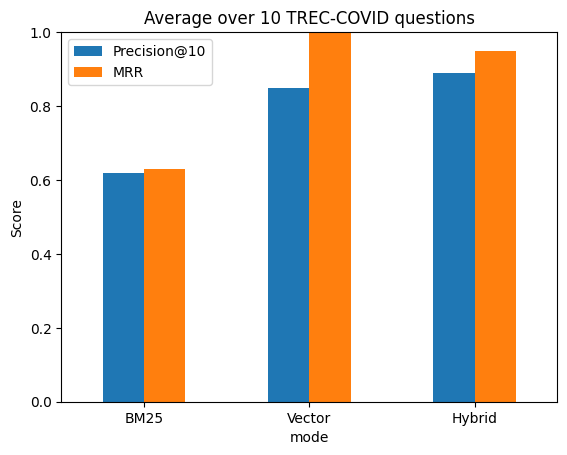

In [28]:
overall.plot.bar(rot=0, ylim=(0, 1), title="Average over 10 TREC-COVID questions")
plt.ylabel("Score")
plt.show()

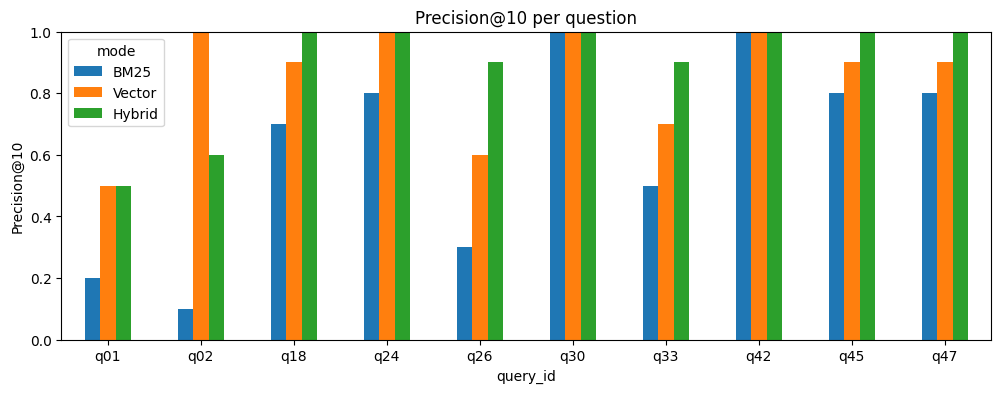

In [29]:
per_question = scores.pivot_table(index="query_id", columns="mode", values="Precision@10")[["BM25", "Vector", "Hybrid"]]
per_question.plot.bar(rot=0, ylim=(0, 1), figsize=(12, 4), title="Precision@10 per question")
plt.ylabel("Precision@10")
plt.show()

In [30]:
top = per_question.max(axis=1)
print("Questions where each mode had the best (or joint best) Precision@10:")
(per_question.eq(top, axis=0)).sum()

Questions where each mode had the best (or joint best) Precision@10:


mode
BM25      2
Vector    5
Hybrid    9
dtype: int64

## Findings

| Mode | Precision@10 | MRR |
|---|---|---|
| BM25 | 0.62 | 0.63 |
| Vector | 0.85 | **1.00** |
| Hybrid | **0.89** | 0.95 |

- **Hybrid is the best overall**: the highest Precision@10, and best or joint best on 9 of the 10 questions.
- **Vector always puts a relevant paper first** (MRR 1.00), so a user sees something useful immediately.
- **BM25 is weakest on natural-language questions**, which are full of words like "what", "how" and "does" that carry no meaning.
  On *"how does the coronavirus respond to changes in the weather"* BM25 scores 0.1 against vector's 1.0,
  because most relevant papers say "temperature" (32 of 42) or "humidity" (25), and only 16 say "weather".
- **When the question contains a precise term**, such as "remdesivir" or "Vitamin D", all three modes are perfect (1.0).
- **Combining helps**: hybrid beats both BM25 and vector on *initial symptoms* (0.9 vs 0.3 and 0.6)
  and *vaccine candidates* (0.9 vs 0.5 and 0.7), because papers found by both methods rise to the top.